# 🤖 Forecasting Weekly Product Demand — Part 4: Features and LightGBM

**Goal of this notebook:** build features in a reusable module (`src/features.py`), train one **global LightGBM** model for all 100 products, and compare it with the best baseline (13-week moving average, validation WAPE **57.1%**) on exactly the same folds.

**Forecasting setup (direct):** at a forecast origin T, all features are built only from weeks up to T, and the model forecasts each of the next 8 weeks, with the horizon h given as a feature. This avoids feeding the model's own forecasts back in (recursive error build-up).

## 1. Setup

The feature code lives in `src/features.py`, not in this notebook, because the API (`app/main.py`) must build **exactly the same features** at prediction time.

In [17]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # so "src" can be imported
PROCESSED_DIR = ROOT / "data" / "processed"

from src.features import (FEATURES, CATEGORICAL, HORIZON, week_calendar,
                          make_features, build_training_set)

weekly = pd.read_parquet(PROCESSED_DIR / "weekly_demand.parquet")
products = pd.read_csv(PROCESSED_DIR / "selected_products.csv",
                       dtype={"StockCode": "string"}).set_index("StockCode")
Y = weekly.pivot(index="week", columns="StockCode", values="units")
weeks = Y.index

FOLD_ENDS = [71, 79, 87, 95]
FOLD_NAMES = ["val 1", "val 2", "val 3", "test"]

print(f"Y: {Y.shape}, features: {len(FEATURES)}")

Y: (104, 100), features: 20


## 2. Check the Features

### 2.1 — Calendar and holiday features

Holiday weeks from Part 2 should be flagged correctly: Easter and other UK bank holidays, and the Christmas and New Year weeks (the shop was closed in the New Year weeks).

In [18]:
cal = week_calendar(weeks)
special = cal[(cal["n_holidays"] > 0) | (cal["is_xmas_week"] == 1) | (cal["is_newyear_week"] == 1)]
special

,week_of_year,month,n_holidays,weeks_to_xmas,is_xmas_week,is_newyear_week
week,,,,,,
2009-12-21,52,12,2,0,1,0
2009-12-28,53,12,2,51,0,1
2010-03-29,13,4,1,38,0,0
2010-04-05,14,4,1,37,0,0
2010-05-03,18,5,1,33,0,0
2010-05-31,22,6,1,29,0,0
2010-08-30,35,9,1,16,0,0
2010-12-20,51,12,2,0,1,0
2010-12-27,52,12,3,51,0,1


📌 **Reading this:** The calendar picks up every UK bank holiday in the period: Easter (two holidays across the Good Friday and Easter Monday weeks), the May and August bank holidays, and the Christmas and New Year weeks. The two New Year weeks (28 Dec 2009 and 27 Dec 2010) are exactly the weeks the shop was closed in Part 2, and they are now flagged with `is_newyear_week = 1`.

### 2.2 — Example feature rows

Features for the top product at the origin of fold *val 1* (18 April 2011), for horizons 1–8. Level-type features are divided by the product's 13-week average (`scale`), so a value of 1.0 means "same as recent average".

In [19]:
f = make_features(Y, FOLD_ENDS[0])
top = products.index[0]
cols = ["lag_1", "rmean_4", "rmean_8", "ly_smooth", "yoy_ratio",
        "season_ratio", "n_holidays", "weeks_to_xmas", "scale"]
f[f["StockCode"] == top].set_index("target_week")[cols].round(2)

,lag_1,rmean_4,rmean_8,ly_smooth,yoy_ratio,season_ratio,n_holidays,weeks_to_xmas,scale
target_week,,,,,,,,,
2011-04-25,1.61,1.66,1.2,0.71,1.48,1.06,2,34,1198.69
2011-05-02,1.61,1.66,1.2,0.63,1.48,0.94,1,33,1198.69
2011-05-09,1.61,1.66,1.2,0.64,1.48,0.94,0,32,1198.69
2011-05-16,1.61,1.66,1.2,0.59,1.48,0.87,0,31,1198.69
2011-05-23,1.61,1.66,1.2,0.92,1.48,1.36,0,30,1198.69
2011-05-30,1.61,1.66,1.2,0.78,1.48,1.16,1,29,1198.69
2011-06-06,1.61,1.66,1.2,0.78,1.48,1.15,0,28,1198.69
2011-06-13,1.61,1.66,1.2,0.92,1.48,1.36,0,27,1198.69


📌 **Reading this:** For the top product, the recent-history features (`lag_1`, `rmean_4`, `rmean_8`) are the same for all 8 horizons, because they describe the product **at the origin**. What changes with the horizon are the target-week features: last year's smoothed demand (`ly_smooth`, `season_ratio`), the number of holidays, and the weeks left until Christmas. `yoy_ratio` = 1.48 shows this product is selling about 48% more than a year earlier, which a pure "same week last year" forecast would miss.

### 2.3 — Leakage test

If the features truly use only past data, **changing every week after the origin must not change any feature**. We replace all future sales with an absurd value and check that the features are identical.

In [20]:
origin = FOLD_ENDS[0]
Y_fake = Y.copy()
Y_fake.iloc[origin + 1 :] = 999_999          # garbage in every future week

pd.testing.assert_frame_equal(make_features(Y, origin), make_features(Y_fake, origin))
print("PASS - features do not use any data after the forecast origin")

PASS - features do not use any data after the forecast origin


📌 **Reading this:** Replacing every future week with 999,999 left every feature unchanged, so `make_features` only reads data up to the forecast origin. This is the most important guarantee for an honest forecast evaluation, and the same test will be part of the API's test suite.

## 3. First LightGBM Model

**How it works for each validation fold:**
1. `build_training_set` takes only the weeks up to the fold's origin, caps one-off bulk weeks (fence from those weeks only), and creates one row per (product, origin, horizon) with its features and target.
2. One **global** LightGBM model is trained on all products together, so products can learn from each other's patterns.
3. The model forecasts the next 8 weeks from the origin, and we score it on the **raw** (uncapped) actual sales with the same `evaluate` function as Part 3.

**Training choices:**
- **Target = units ÷ scale** (the product's 13-week average), so all products are on a similar scale.
- **Objective = L1 (absolute error)** with **sample weight = scale**. Together these minimise the absolute error in **units**, which is exactly what WAPE measures.
- Starting hyperparameters are reasonable defaults. They will be tuned in section 4.

In [21]:
import lightgbm as lgb
from src.features import cap_outliers
from src.evaluation import evaluate, moving_average_forecast

PARAMS = dict(
    objective="l1", n_estimators=600, learning_rate=0.03, num_leaves=15,
    min_child_samples=50, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, verbose=-1,
)

def fit_and_forecast(Y, e, params=PARAMS):
    """Train on weeks 0..e and forecast weeks e+1..e+8 (array: weeks x products)."""
    train_rows, fence = build_training_set(Y, e)
    model = lgb.LGBMRegressor(**params)
    model.fit(train_rows[FEATURES], train_rows["y"],
              sample_weight=train_rows["scale"], categorical_feature=CATEGORICAL)

    hist = cap_outliers(Y.iloc[: e + 1], fence)      # same capping as in training
    rows = make_features(hist, e)
    pred = model.predict(rows[FEATURES]) * rows["scale"].to_numpy()
    pred = np.clip(pred, 0, None)                    # demand can't be negative
    return model, pred.reshape(HORIZON, -1), len(train_rows)

### 3.1 — Train and score on the 3 validation folds

In [22]:
rows = []
for name, e in zip(FOLD_NAMES, FOLD_ENDS):
    if name == "test":
        continue
    model, fc, n_rows = fit_and_forecast(Y, e)
    actual = Y.iloc[e + 1 : e + 1 + HORIZON].to_numpy()
    train = Y.iloc[: e + 1]
    rows.append({"fold": name, "method": "LightGBM", "train rows": n_rows,
                 **evaluate(actual, fc, train)})
    rows.append({"fold": name, "method": "moving avg 13", "train rows": None,
                 **evaluate(actual, moving_average_forecast(Y, e), train)})
    print(f"{name}: trained on {n_rows:,} rows")

lgb_results = pd.DataFrame(rows)

print("\nWAPE per fold:")
print(lgb_results.pivot(index="method", columns="fold", values="WAPE").round(3))

compare = (lgb_results.groupby("method")[["MAE", "WAPE", "Bias", "MASE", "WAPE (no bulk weeks)"]]
           .mean().round(3))
compare

val 1: trained on 44,400 rows
val 2: trained on 50,800 rows
val 3: trained on 57,200 rows

WAPE per fold:
fold           val 1  val 2  val 3
method                            
LightGBM       0.551  0.565  0.537
moving avg 13  0.542  0.596  0.574


,MAE,WAPE,Bias,MASE,WAPE (no bulk weeks)
method,,,,,
LightGBM,136.396,0.551,-0.147,0.748,0.531
moving avg 13,141.238,0.571,-0.046,0.775,0.552


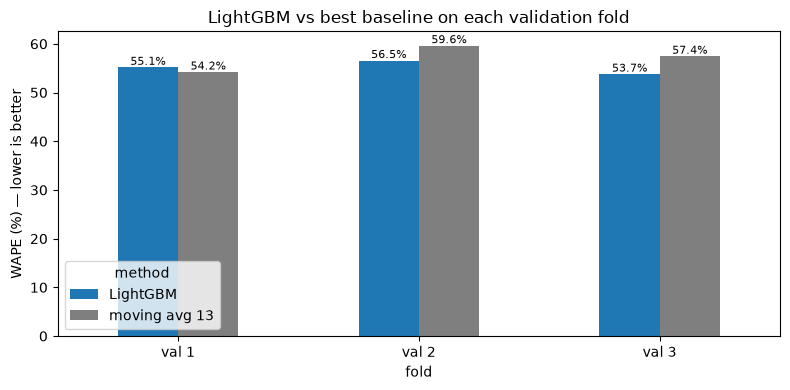

In [23]:
wape = lgb_results.pivot(index="fold", columns="method", values="WAPE") * 100

ax = wape.plot(kind="bar", figsize=(8, 4), color=["tab:blue", "tab:grey"], rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", fontsize=8)
ax.set_ylabel("WAPE (%) — lower is better")
ax.set_title("LightGBM vs best baseline on each validation fold")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- The first LightGBM model reaches a validation WAPE of **55.1%**, against **57.1%** for the 13-week moving average. It wins 2 of the 3 folds (val 2 and val 3) and loses val 1 by about 1 point. MASE improves from 0.775 to 0.748. That is a real but **modest** gain, as expected from the weak autocorrelation in Part 2.
- The moving-average score matches Part 3 exactly (57.1%), so both notebooks use the same evaluation.
- **Bias is −14.7%**: the model under-forecasts. The L1 objective predicts the **median**, and weekly sales are right-skewed (occasional big weeks), so the median sits below the mean. That is good for WAPE but risky for stock planning, because under-forecasting leads to stock-outs. We'll let tuning also try other objectives (Huber, Tweedie), and the safety stock in Part 5 will use the p90 forecast.

## 4. Hyperparameter Tuning with Optuna

**Optuna** searches for good hyperparameters. Like `RandomizedSearchCV`, it tries many settings, but it uses the results of earlier trials to choose the next one (a TPE sampler), so it finds good settings with fewer trials.

- **Score of a trial** = average WAPE over the 3 validation folds (the test fold is never used).
- **Search space:** the objective (L1, Huber or Tweedie), number of trees, learning rate, tree size, minimum rows per leaf, row/column sampling and L2 regularisation.
- The default settings from section 3 are tried first, so tuning can never end up worse than our starting point.
- To save time, features for each fold are built **once** and reused by every trial.

**Caveat:** because we pick the best of many trials on the validation folds, the tuned validation score is slightly optimistic. The untouched test fold gives the honest number.

In [24]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# build features once per validation fold, reuse in every trial
VAL = [(n, e) for n, e in zip(FOLD_NAMES, FOLD_ENDS) if n != "test"]
cache = {}
for name, e in VAL:
    train_rows, fence = build_training_set(Y, e)
    pred_rows = make_features(cap_outliers(Y.iloc[: e + 1], fence), e)
    cache[name] = dict(e=e, train_rows=train_rows, pred_rows=pred_rows)

def val_forecasts(params):
    """Train one model per validation fold and return its 8-week forecasts."""
    out = {}
    for name, c in cache.items():
        tr = c["train_rows"]
        model = lgb.LGBMRegressor(**params)
        model.fit(tr[FEATURES], tr["y"], sample_weight=tr["scale"], categorical_feature=CATEGORICAL)
        rows = c["pred_rows"]
        pred = np.clip(model.predict(rows[FEATURES]) * rows["scale"].to_numpy(), 0, None)
        out[name] = pred.reshape(HORIZON, -1)
    return out

def val_scores(params, label):
    rows = []
    for name, fc in val_forecasts(params).items():
        e = cache[name]["e"]
        actual = Y.iloc[e + 1 : e + 1 + HORIZON].to_numpy()
        rows.append({"fold": name, "method": label, **evaluate(actual, fc, Y.iloc[: e + 1])})
    return pd.DataFrame(rows)

def objective(trial):
    params = dict(
        objective=trial.suggest_categorical("objective", ["l1", "huber", "tweedie"]),
        n_estimators=trial.suggest_int("n_estimators", 200, 1200, step=100),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        num_leaves=trial.suggest_int("num_leaves", 7, 63),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 300, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        subsample_freq=1, random_state=42, verbose=-1,
    )
    return val_scores(params, "trial")["WAPE"].mean()

### 4.1 — Run the search (30 trials)

In [25]:
N_TRIALS = 30

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
# first trial = the default settings from section 3
study.enqueue_trial({k: PARAMS[k] for k in ["objective", "n_estimators", "learning_rate", "num_leaves",
                                            "min_child_samples", "subsample", "colsample_bytree"]}
                    | {"reg_lambda": 1e-3})
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

BEST_PARAMS = study.best_params | dict(subsample_freq=1, random_state=42, verbose=-1)
print(f"Default WAPE: {study.trials[0].value:.3f}")
print(f"Best WAPE   : {study.best_value:.3f}")
study.best_params

Best trial: 29. Best value: 0.538788: 100%|██████████| 30/30 [03:38<00:00,  7.29s/it]

Default WAPE: 0.551
Best WAPE   : 0.539


{'objective': 'l1',
 'n_estimators': 400,
 'learning_rate': 0.012753175869578177,
 'num_leaves': 8,
 'min_child_samples': 280,
 'subsample': 0.8935158536148141,
 'colsample_bytree': 0.5017174397011703,
 'reg_lambda': 1.2126131029669294}

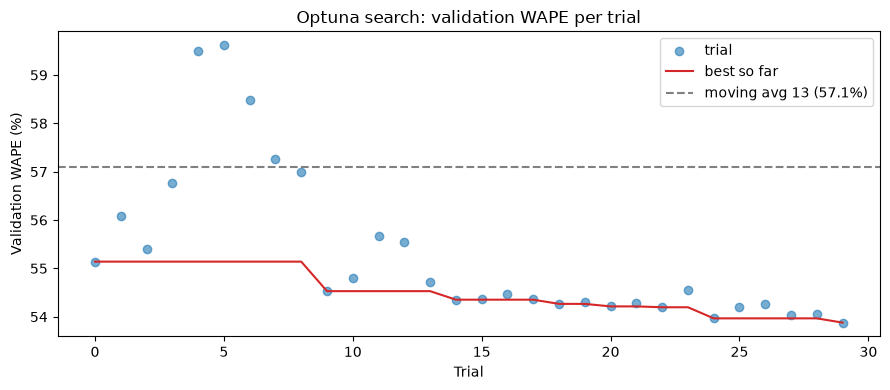

In [26]:
hist = study.trials_dataframe()

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(hist["number"], hist["value"] * 100, color="tab:blue", alpha=0.6, label="trial")
ax.plot(hist["number"], hist["value"].cummin() * 100, color="tab:red", label="best so far")
ax.axhline(57.1, color="grey", linestyle="--", label="moving avg 13 (57.1%)")
ax.set_xlabel("Trial")
ax.set_ylabel("Validation WAPE (%)")
ax.set_title("Optuna search: validation WAPE per trial")
ax.legend()
plt.tight_layout()
plt.show()

📌 **Reading this:** The first trial (default settings, 55.1%) was already good. Some early trials were much worse (up to ~59.6%, worse than the baseline), but from about trial 9 onwards the search kept finding better settings. It ends at **53.9%**, well below the 57.1% baseline line. The curve is flattening near the end, so more trials would likely give only small gains.

### 4.2 — Default vs tuned vs baseline

In [27]:
ma_rows = []
for name, c in cache.items():
    e = c["e"]
    actual = Y.iloc[e + 1 : e + 1 + HORIZON].to_numpy()
    ma_rows.append({"fold": name, "method": "moving avg 13",
                    **evaluate(actual, moving_average_forecast(Y, e), Y.iloc[: e + 1])})

all_results = pd.concat([
    pd.DataFrame(ma_rows),
    val_scores(PARAMS, "LightGBM (default)"),
    val_scores(BEST_PARAMS, "LightGBM (tuned)"),
])

print("WAPE per fold:")
print(all_results.pivot(index="method", columns="fold", values="WAPE").round(3), "\n")
(all_results.groupby("method")[["MAE", "WAPE", "Bias", "MASE", "WAPE (no bulk weeks)"]]
 .mean().sort_values("WAPE").round(3))

WAPE per fold:
fold                val 1  val 2  val 3
method                                 
LightGBM (default)  0.551  0.565  0.537
LightGBM (tuned)    0.541  0.550  0.526
moving avg 13       0.542  0.596  0.574 



,MAE,WAPE,Bias,MASE,WAPE (no bulk weeks)
method,,,,,
LightGBM (tuned),133.288,0.539,-0.172,0.737,0.516
LightGBM (default),136.396,0.551,-0.147,0.748,0.531
moving avg 13,141.238,0.571,-0.046,0.775,0.552


📌 **Reading this:**
- The tuned model is the best on every metric except bias: WAPE **53.9%** vs 57.1% for the moving average (about 6% less error), MASE **0.737**, and WAPE without bulk weeks **51.6%**. It is now at least as good as the baseline on all three folds (val 1 is a near-tie: 54.1% vs 54.2%).
- **Bias got worse: −17.2%.** The tuned model is simpler and more cautious, and with the L1 objective it predicts the median, which is below the mean for right-skewed sales. The median is still the right point forecast for WAPE, but **stock should not be planned from it**. Next we add p10/p90 forecasts, and Part 5 will plan stock from the upper quantile.

## 5. Forecast Ranges: Quantile Models (p10, p50, p90)

A single number hides uncertainty. **Quantile regression** trains a model to predict a chosen percentile of demand instead of the median:
- **p10**: demand should fall **below** this in about 10% of weeks
- **p50**: the median (the tuned L1 model from section 4)
- **p90**: demand should **exceed** this in only about 10% of weeks. This is what we will use for safety stock in Part 5.

We reuse the tuned hyperparameters and only change the objective to `quantile` with `alpha` = 0.1 or 0.9.

**How we check the ranges:**
- **Coverage**: share of actual weeks that fall between p10 and p90. The target is about **80%**.
- **Pinball loss** (quantile loss): the standard error measure for a quantile forecast. It penalises being on the "wrong side" of the quantile more heavily. We divide it by total demand, like WAPE, so lower is better.
- **Width ÷ demand**: how wide the range is compared to actual demand. Narrower is more useful, as long as coverage stays near 80%.

In [28]:
QUANTILES = {"p10": 0.1, "p50": 0.5, "p90": 0.9}

def quantile_params(alpha):
    if alpha == 0.5:
        return BEST_PARAMS                    # the tuned L1 model = median
    return BEST_PARAMS | {"objective": "quantile", "alpha": alpha}

q_raw = {q: val_forecasts(quantile_params(a)) for q, a in QUANTILES.items()}

# separate models can occasionally cross (p10 > p50); sorting keeps p10 <= p50 <= p90
q_fc = {}
for name in cache:
    stacked = np.sort(np.stack([q_raw[q][name] for q in QUANTILES]), axis=0)
    q_fc[name] = dict(zip(QUANTILES, stacked))

def pinball(actual, pred, alpha):
    """Quantile (pinball) loss, divided by total demand."""
    diff = actual - pred
    return np.maximum(alpha * diff, (alpha - 1) * diff).sum() / actual.sum()

rows = []
for name, c in cache.items():
    e = c["e"]
    actual = Y.iloc[e + 1 : e + 1 + HORIZON].to_numpy()
    f = q_fc[name]
    rows.append({
        "fold": name,
        "coverage p10-p90": ((actual >= f["p10"]) & (actual <= f["p90"])).mean(),
        "below p10": (actual < f["p10"]).mean(),
        "above p90": (actual > f["p90"]).mean(),
        "pinball p10": pinball(actual, f["p10"], 0.1),
        "pinball p50": pinball(actual, f["p50"], 0.5),
        "pinball p90": pinball(actual, f["p90"], 0.9),
        "width / demand": (f["p90"] - f["p10"]).sum() / actual.sum(),
    })

interval = pd.DataFrame(rows).set_index("fold")
print(interval.round(3), "\n")
print("Average over folds:")
interval.mean().round(3)

       coverage p10-p90  below p10  above p90  pinball p10  pinball p50  \
fold                                                                      
val 1             0.796      0.109      0.095        0.084        0.270   
val 2             0.770      0.120      0.110        0.085        0.275   
val 3             0.810      0.075      0.115        0.078        0.263   

       pinball p90  width / demand  
fold                                
val 1        0.178           1.751  
val 2        0.198           1.608  
val 3        0.196           1.654   

Average over folds:


coverage p10-p90    0.792
below p10           0.101
above p90           0.107
pinball p10         0.083
pinball p50         0.269
pinball p90         0.190
width / demand      1.671
dtype: float64

📌 **Reading this:** The ranges are **well calibrated**: on average **79.2%** of actual weeks fall between p10 and p90 (target 80%), 10.1% fall below p10 and 10.7% above p90 (targets 10% each). So when the model says "80% chance demand is in this range", that is true about 80% of the time, which is what makes the p90 safe to plan stock from. The price of that honesty is width: the p10–p90 range is on average **1.67× the actual demand**, which reflects how unpredictable weekly product demand really is.

### 5.1 — What does a range forecast look like?

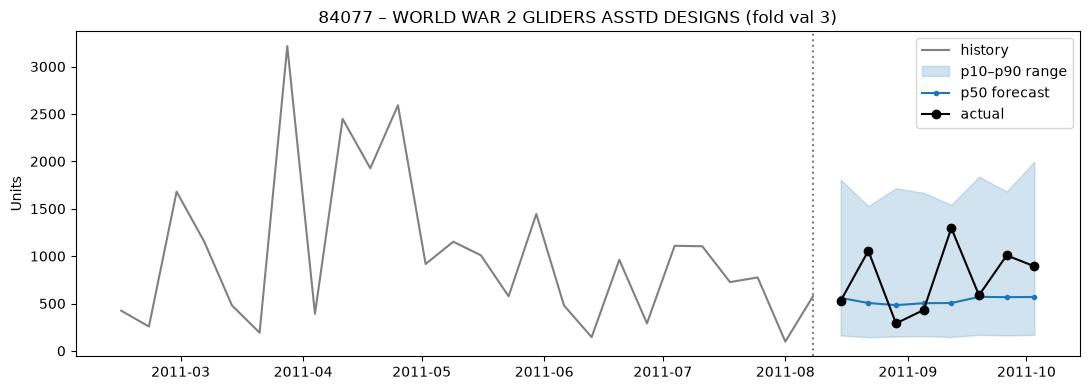

In [29]:
code = products.index[0]
name = "val 3"
e = cache[name]["e"]
j = Y.columns.get_loc(code)
future = weeks[e + 1 : e + 1 + HORIZON]
f = q_fc[name]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weeks[e - 25 : e + 1], Y[code].iloc[e - 25 : e + 1], color="grey", label="history")
ax.fill_between(future, f["p10"][:, j], f["p90"][:, j], color="tab:blue", alpha=0.2, label="p10–p90 range")
ax.plot(future, f["p50"][:, j], color="tab:blue", marker=".", label="p50 forecast")
ax.plot(future, Y[code].iloc[e + 1 : e + 1 + HORIZON], color="black", marker="o", label="actual")
ax.axvline(weeks[e], color="grey", linestyle=":")
ax.set_ylabel("Units")
ax.set_title(f"{code} – {products.loc[code, 'Description'][:40]} (fold {name})")
ax.legend()
plt.tight_layout()
plt.show()

📌 **Reading this:** All eight actual weeks for the top product fall inside the p10–p90 band. The p50 line (about 480–570 units) sits **below** 5 of the 8 actual weeks (300–1,300). That is the under-forecasting bias from section 4 again: the median is a good point forecast for WAPE, but for stock decisions the upper part of the range matters, which is why Part 5 uses p90.

## 6. Final Test: Gift-Season Peak (10 Oct – 28 Nov 2011)

Every choice so far (features, hyperparameters, quantiles) was made on the validation folds only. Now we train on all weeks up to 3 October 2011 and forecast the **test fold once**. Whatever the result, the model is **not changed afterwards**; otherwise the test score would no longer be an honest estimate.

We compare with the best baseline (13-week moving average) and with seasonal naive, which might do better in the peak season because it copies last year's peak.

In [30]:
e = FOLD_ENDS[-1]
print(f"Train: {weeks[0]:%d %b %Y} – {weeks[e]:%d %b %Y}  ({e + 1} weeks)")
print(f"Test : {weeks[e + 1]:%d %b %Y} – {weeks[e + HORIZON]:%d %b %Y}  ({HORIZON} weeks)")

train_rows, fence = build_training_set(Y, e)
pred_rows = make_features(cap_outliers(Y.iloc[: e + 1], fence), e)

raw = []
for q, a in QUANTILES.items():
    m = lgb.LGBMRegressor(**quantile_params(a))
    m.fit(train_rows[FEATURES], train_rows["y"],
          sample_weight=train_rows["scale"], categorical_feature=CATEGORICAL)
    pred = m.predict(pred_rows[FEATURES]) * pred_rows["scale"].to_numpy()
    raw.append(np.clip(pred, 0, None).reshape(HORIZON, -1))
test_fc = dict(zip(QUANTILES, np.sort(np.stack(raw), axis=0)))

actual = Y.iloc[e + 1 : e + 1 + HORIZON].to_numpy()
train = Y.iloc[: e + 1]
baselines = {
    "moving avg 13": moving_average_forecast(Y, e),
    "seasonal naive": Y.iloc[e + 1 - 52 : e + 1 - 52 + HORIZON].to_numpy(),
}

test_results = pd.DataFrame(
    [{"method": m, **evaluate(actual, fc, train)} for m, fc in baselines.items()]
    + [{"method": "LightGBM (tuned, p50)", **evaluate(actual, test_fc["p50"], train)}]
).set_index("method")

cov = ((actual >= test_fc["p10"]) & (actual <= test_fc["p90"])).mean()
print(f"Training rows: {len(train_rows):,}")
print(f"Coverage p10-p90: {cov:.1%}   below p10: {(actual < test_fc['p10']).mean():.1%}   "
      f"above p90: {(actual > test_fc['p90']).mean():.1%}")
print(f"Pinball p90: {pinball(actual, test_fc['p90'], 0.9):.3f}\n")
test_results.round(3)

Train: 07 Dec 2009 – 03 Oct 2011  (96 weeks)
Test : 10 Oct 2011 – 28 Nov 2011  (8 weeks)
Training rows: 63,600
Coverage p10-p90: 81.8%   below p10: 8.6%   above p90: 9.6%
Pinball p90: 0.194



,MAE,WAPE,Bias,MASE,WAPE (no bulk weeks),bulk weeks
method,,,,,,
moving avg 13,173.734,0.579,-0.143,0.996,0.525,31
seasonal naive,250.329,0.835,0.364,1.302,0.936,31
"LightGBM (tuned, p50)",160.179,0.534,-0.183,0.925,0.475,31


📌 **Reading this:**
- On the untouched test fold (gift-season peak), the tuned LightGBM reaches a **WAPE of 53.4%**, against **57.9%** for the 13-week moving average and **83.5%** for seasonal naive. Without bulk-order weeks it is **47.5%** vs 52.5%.
- The test WAPE is almost the same as the validation WAPE (53.9%), so tuning did not overfit the validation folds.
- The ranges stay **well calibrated** even in the peak: **81.8%** of actual weeks fall between p10 and p90 (8.6% below, 9.6% above).
- Bias is **−18.3%**: the median forecast is too low, especially in the peak (see 6.1).
- Seasonal naive over-forecasts by 36%, because it copies last year's peak at last year's higher level.

### 6.1 — Error by horizon, and the total forecast

Left: WAPE for each week ahead (h = 1 is next week, h = 8 is eight weeks ahead). Right: total units of all 100 products, actual vs forecasts.

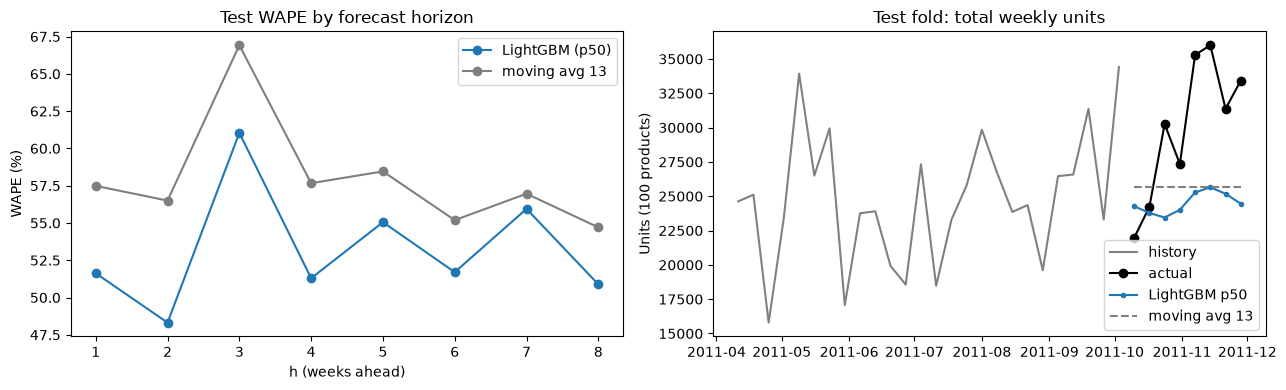

,LightGBM (p50),moving avg 13
h (weeks ahead),,
1,0.516,0.575
2,0.483,0.565
3,0.610,0.669
4,0.513,0.577
5,0.551,0.585
6,0.517,0.552
7,0.559,0.570
8,0.509,0.547


In [31]:
def wape_by_h(fc):
    return np.abs(fc - actual).sum(axis=1) / actual.sum(axis=1)

by_h = pd.DataFrame({
    "LightGBM (p50)": wape_by_h(test_fc["p50"]),
    "moving avg 13": wape_by_h(baselines["moving avg 13"]),
}, index=pd.Index(range(1, HORIZON + 1), name="h (weeks ahead)"))

test_weeks = weeks[e + 1 : e + 1 + HORIZON]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

(by_h * 100).plot(ax=axes[0], marker="o", color=["tab:blue", "tab:grey"])
axes[0].set_ylabel("WAPE (%)")
axes[0].set_title("Test WAPE by forecast horizon")

axes[1].plot(weeks[e - 25 : e + 1], train.sum(axis=1).iloc[-26:], color="grey", label="history")
axes[1].plot(test_weeks, actual.sum(axis=1), color="black", marker="o", label="actual")
axes[1].plot(test_weeks, test_fc["p50"].sum(axis=1), color="tab:blue", marker=".", label="LightGBM p50")
axes[1].plot(test_weeks, baselines["moving avg 13"].sum(axis=1), color="tab:grey",
             linestyle="--", label="moving avg 13")
axes[1].set_ylabel("Units (100 products)")
axes[1].set_title("Test fold: total weekly units")
axes[1].legend()
plt.tight_layout()
plt.show()

by_h.round(3)

📌 **Reading this:**
- **LightGBM beats the moving average at every horizon**, from 1 to 8 weeks ahead (for example 48.3% vs 56.5% at h = 2). The error does not grow much with the horizon, because weekly noise matters more than how far ahead we look.
- **Main weakness:** total demand climbed from about 22,000 to 36,000 units in November, but the median forecast stayed almost flat at about 23,400–25,600. The model **under-forecasts the gift-season ramp-up**. Likely reasons: only one earlier peak (2010) to learn from, tuning on off-peak weeks, and a 2010 peak that looked different from 2011. This is the most important limitation of the model. In practice, planning stock from **p90** (well calibrated even here) covers most of this risk.

## 7. Train the Final Model and Save It

The test score above is our honest estimate of accuracy. For the app we now retrain the same setup (tuned parameters, p10/p50/p90) on **all 104 weeks**, so it can forecast the real future (from December 2011).

Everything the API needs goes into **one file**, `models/forecast_bundle_v1.pkl`:
- the three LightGBM models (p10, p50, p90)
- the feature list and the tuned parameters
- the outlier fence per product (the API must cap history the same way as training)
- the **history snapshot** (weekly units per product), because features like lags and last year's demand need past sales
- product names and the test metrics, for display

Keeping everything in one bundle means the API can't accidentally load a model with the wrong feature list or fence.

In [32]:
import joblib

MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

LAST = len(weeks) - 1                       # train on all weeks
train_rows, fence = build_training_set(Y, LAST)

final_models = {}
for q, a in QUANTILES.items():
    m = lgb.LGBMRegressor(**quantile_params(a))
    m.fit(train_rows[FEATURES], train_rows["y"],
          sample_weight=train_rows["scale"], categorical_feature=CATEGORICAL)
    final_models[q] = m

lgb_test = test_results.loc["LightGBM (tuned, p50)"]
test_summary = {
    "test_period": f"{weeks[FOLD_ENDS[-1] + 1].date()} to {weeks[FOLD_ENDS[-1] + HORIZON].date()}",
    "WAPE": round(float(lgb_test["WAPE"]), 3),
    "WAPE_baseline_ma13": round(float(test_results.loc["moving avg 13", "WAPE"]), 3),
    "Bias": round(float(lgb_test["Bias"]), 3),
    "coverage_p10_p90": round(float(cov), 3),
}

bundle = {
    "models": final_models,
    "quantiles": QUANTILES,
    "params": BEST_PARAMS,
    "features": FEATURES,
    "categorical": CATEGORICAL,
    "horizon": HORIZON,
    "fence": fence,
    "history": Y,
    "product_names": products["Description"].to_dict(),
    "trained_until": str(weeks[LAST].date()),
    "test_metrics": test_summary,
}
joblib.dump(bundle, MODELS_DIR / "forecast_bundle_v1.pkl")

size_mb = (MODELS_DIR / "forecast_bundle_v1.pkl").stat().st_size / 1e6
print(f"Trained on {len(train_rows):,} rows, up to {bundle['trained_until']}")
print(f"Saved models/forecast_bundle_v1.pkl ({size_mb:.2f} MB)")
test_summary

Trained on 70,000 rows, up to 2011-11-28
Saved models/forecast_bundle_v1.pkl (1.43 MB)


{'test_period': '2011-10-10 to 2011-11-28',
 'WAPE': 0.534,
 'WAPE_baseline_ma13': 0.579,
 'Bias': -0.183,
 'coverage_p10_p90': 0.818}

📌 **Reading this:** The final models were trained on 70,000 rows covering all data up to 28 November 2011. The whole bundle (3 models, feature list, fence, history and metadata) is only **1.43 MB**, small enough to ship with the API on a free hosting tier. The test metrics stored in the bundle (WAPE 53.4% vs 57.9% for the baseline, coverage 81.8%) are the honest accuracy estimate we will show in the app and README.

### 7.1 — Check: load the bundle and forecast the real future

We reload the saved file (exactly as the API will) and forecast the 8 weeks after the data ends, using `src/forecast.py`, the same function the API will call.

In [33]:
from src.forecast import forecast

loaded = joblib.load(MODELS_DIR / "forecast_bundle_v1.pkl")
future = forecast(loaded)

print(f"Forecast rows: {len(future):,}  ({future['StockCode'].nunique()} products x {future['h'].nunique()} weeks)")
print(f"Forecast weeks: {future['week'].min():%d %b %Y} to {future['week'].max():%d %b %Y}\n")

top = str(products.index[0])
print(f"{top} – {loaded['product_names'][products.index[0]]}")
future[future["StockCode"] == top]

Forecast rows: 800  (100 products x 8 weeks)
Forecast weeks: 05 Dec 2011 to 23 Jan 2012

84077 – WORLD WAR 2 GLIDERS ASSTD DESIGNS


,StockCode,week,h,p10,p50,p90
78,84077,2011-12-05,1,372.5,665.0,1773.7
178,84077,2011-12-12,2,280.0,650.3,1805.4
278,84077,2011-12-19,3,73.6,451.1,1441.3
378,84077,2011-12-26,4,0.5,132.4,327.6
478,84077,2012-01-02,5,128.5,450.0,1099.3
578,84077,2012-01-09,6,131.6,458.8,1275.7
678,84077,2012-01-16,7,130.6,513.5,1337.0
778,84077,2012-01-23,8,200.4,514.6,1371.6


📌 **Reading this:** The reloaded bundle forecasts all 100 products for the 8 weeks after the data ends (5 Dec 2011 – 23 Jan 2012). For the top product, normal weeks are forecast at about 450–665 units, but the week of **26 December drops to 132** (p10 close to 0). The model has learned from the `is_newyear_week` feature that the shop is closed or nearly closed between Christmas and New Year, without being told so directly.

**Note:** the raw data actually runs until 9 December 2011, but that partial week was dropped in Part 2, so the first forecast week (5 Dec) is partly "known". In real use, the model would always forecast from the latest complete week.

## 8. Summary

**Setup**
- Features live in `src/features.py` (shared with the API): recent lags, rolling means and spread, smoothed last-year demand, a year-over-year ratio, calendar and UK holiday flags, the horizon and the product. All are scaled by the product's 13-week average. A leakage test confirms that no feature uses data after the forecast origin.
- One **global LightGBM** model for all 100 products, direct 8-week forecasts, L1 objective with scale weights (minimises error in units). One-off bulk weeks are capped in training only, with the fence computed from training data.

**Results**

| | Validation WAPE (3 folds) | Test WAPE (peak, 10 Oct – 28 Nov 2011) |
|---|---|---|
| Seasonal naive | 90.6% | 83.5% |
| Moving average 13 (best baseline) | 57.1% | 57.9% |
| LightGBM, default | 55.1% | — |
| **LightGBM, tuned (Optuna, 30 trials)** | **53.9%** | **53.4%** |

- The tuned model beats the best baseline on every validation fold and at **every horizon** of the test fold. Test and validation scores are close, so tuning did not overfit.
- **p10–p90 ranges are well calibrated**: 79.2% coverage on validation and 81.8% on test (target 80%).
- The model learned the Christmas / New Year closure weeks on its own.

**Limitations**
- **Under-forecasting (bias about −18%)**: the median forecast is too low, and the model misses most of the November ramp-up. Only one earlier peak to learn from, and tuning on off-peak weeks. Stock should be planned from p90, not p50.
- Weekly product demand is very noisy, so the gain over a simple moving average is real but modest (about 3 WAPE points on validation and 4.5 on test).
- No price or promotion data, and no forecasts for new products (cold start).

**Saved:** `models/forecast_bundle_v1.pkl` (models, feature list, fence, history snapshot, product names, test metrics), loaded by `src/forecast.py`.

**Next (Part 5):** SHAP explanations, error analysis, and the business layer (safety stock and reorder point from p90, with a stock-out / overstock simulation).

> **Update (Part 7):** this first model is kept as `models/forecast_bundle_v1.pkl`. Part 7 adds order features; that improved model is saved as `models/forecast_bundle.pkl` and is the one the app uses.